# **Machine Learning approaches to pressing aggressiveness in football**

The territorial-behavior analysis (`territorial_behavior_in_football.ipynb`) established a clear result with event data from four major European leagues: 75 out of 80 teams pressed more aggressively in the opponent's half when playing at home.

But that analysis could only measure pressing *frequency*, that is how often a team contests the ball. When we turned to tracking data (`tracking_defensive_line.ipynb`) and measured positional occupancy, the fraction of a team's players standing in the opponent's half, the home-away difference was far less clear. We concluded that positions alone are too passive a measure to capture pressing behavior: a team can have players deep in the opponent's half without actually pressing.

The SkillCorner open dataset offers something neither data source could provide on its own: event labels and tracking data for the same 20 A-League matches. We first confirm the limitation of tracking data alone: territorial occupancy, measured across all frames, does not clearly separate home from away teams. We then combine both data sources: for each pressing chain identified by SkillCorner's event labels, we extract the full spatial configuration of all 20 outfield players (positions and velocities) at the moment the press begins. This lets us ask: do home teams press *differently*, and do they press *more effectively*? A logistic regression on hand-crafted summary features (compactness, defensive line height, closing speed) serves as a baseline; a deep learning model that ingests the raw spatial configuration tests whether the geometry of pressing contains structure that summary statistics miss.

## Setup

In [1]:
import os
os.environ.pop("MallocStackLogging", None)

import json
import pickle
import urllib.request
import warnings

import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
from kloppy import skillcorner
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from mplsoccer import Pitch

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = "data/skillcorner"
os.makedirs(DATA_DIR, exist_ok=True)

REPO_RAW = "https://raw.githubusercontent.com/SkillCorner/opendata/master"
FPS = 10
SAVGOL_WINDOW = 5
SAVGOL_POLY = 2

In [2]:
%config InlineBackend.figure_format = 'retina'
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

pd.set_option("display.max_columns", None)

# Plot style: real LaTeX when available (best-looking, e.g. local machines with a LaTeX
# install), a LaTeX-free fallback otherwise (Binder/Colab, which don't have LaTeX)
import shutil
import scienceplots

if shutil.which('latex'):
    plt.style.use(['science', 'nature'])
else:
    plt.style.use(['science', 'no-latex', 'nature'])
    plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans']
plt.rcParams['figure.figsize'] = [5, (4.8/6.4)*5]
plt.rcParams['figure.dpi'] = 150

# Nature style pins these to 7pt by default; bump for legibility
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 9
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9

## Data

In [3]:
matches = json.loads(
    urllib.request.urlopen(f"{REPO_RAW}/data/matches.json").read()
)
match_ids = [m["id"] for m in matches]
home_team_ids = {m["id"]: m["home_team"]["id"] for m in matches}

print(f"{len(matches)} A-League matches\n")
for m in matches:
    print(f"  {m['date_time'][:10]}  {m['home_team']['short_name']:>20s} vs {m['away_team']['short_name']}")

20 A-League matches

  2025-05-17        Melbourne V FC vs Auckland FC
  2025-05-09        Western United vs Adelaide United
  2025-05-03        Western United vs Auckland FC
  2025-04-27        Western United vs Sydney FC
  2025-04-12       Wellington P FC vs Melbourne V FC
  2025-04-05        Melbourne City vs CC Mariners
  2025-03-16           Auckland FC vs CC Mariners
  2025-03-15           Perth Glory vs Brisbane FC
  2025-03-08        Melbourne V FC vs CC Mariners
  2025-03-07        Melbourne City vs Macarthur FC
  2025-02-01             Sydney FC vs Adelaide United
  2025-02-01           Auckland FC vs Macarthur FC
  2025-01-26        Western Sydney vs Auckland FC
  2025-01-10        Melbourne V FC vs Western United
  2024-12-31           CC Mariners vs Melbourne City
  2024-12-22        Western Sydney vs Wellington P FC
  2024-12-21           Brisbane FC vs Perth Glory
  2024-12-07           Auckland FC vs Wellington P FC
  2024-11-30           Auckland FC vs Newcastle
  2024

In [4]:
all_chains = []

for mid in match_ids:
    events = pd.read_csv(f"{REPO_RAW}/data/matches/{mid}/{mid}_dynamic_events.csv")
    pressing = events[events["pressing_chain"] == True]
    if pressing.empty:
        continue

    chains = (
        pressing.groupby("pressing_chain_index")
        .agg(
            frame_start=("frame_start", "min"),
            frame_last=("frame_start", "max"),
            pressing_team_id=("team_id", "first"),
            pressing_team=("team_shortname", "first"),
            chain_length=("pressing_chain_length", "first"),
            end_type=("pressing_chain_end_type", "first"),
        )
        .reset_index()
    )
    chains["frame_mid"] = ((chains["frame_start"] + chains["frame_last"]) // 2).astype(int)
    chains["match_id"] = mid
    chains["is_home_pressing"] = chains["pressing_team_id"] == home_team_ids[mid]
    all_chains.append(chains)

chains_df = pd.concat(all_chains, ignore_index=True)
chains_df["label"] = (chains_df["end_type"] == "regain").astype(int)

print(f"{len(chains_df)} pressing chains across {chains_df['match_id'].nunique()} matches\n")
print(chains_df["end_type"].value_counts())
print(f"\nHome team pressing: {chains_df['is_home_pressing'].sum()}")
print(f"Away team pressing: {(~chains_df['is_home_pressing']).sum()}")
print(f"\nMedian chain duration: {((chains_df['frame_last'] - chains_df['frame_start']) / FPS).median():.1f}s")

/var/folders/dy/0dr1rz555tqczw3kw215bzcw0000gn/T/ipykernel_84486/2280491056.py:4: DtypeWarning: Columns (75: game_interruption_before, 77: game_interruption_after, 243: first_line_break_type, 246: second_last_line_break_type, 281: intended_run_behind, 282: push_defensive_line, 283: break_defensive_line, 288: affected_line_breaking_passing_option_id, 290: affected_line_break, 291: affected_line_breaking_passing_option_attempted, 293: affected_line_breaking_passing_option_dangerous, 295: affected_line_breaking_passing_option_run_subtype, 299: pressing_chain_end_type) have mixed types. Specify dtype option on import or set low_memory=False.
  events = pd.read_csv(f"{REPO_RAW}/data/matches/{mid}/{mid}_dynamic_events.csv")


/var/folders/dy/0dr1rz555tqczw3kw215bzcw0000gn/T/ipykernel_84486/2280491056.py:4: DtypeWarning: Columns (295: affected_line_breaking_passing_option_run_subtype) have mixed types. Specify dtype option on import or set low_memory=False.
  events = pd.read_csv(f"{REPO_RAW}/data/matches/{mid}/{mid}_dynamic_events.csv")


/var/folders/dy/0dr1rz555tqczw3kw215bzcw0000gn/T/ipykernel_84486/2280491056.py:4: DtypeWarning: Columns (288: affected_line_breaking_passing_option_id, 290: affected_line_break, 291: affected_line_breaking_passing_option_attempted, 293: affected_line_breaking_passing_option_dangerous, 295: affected_line_breaking_passing_option_run_subtype) have mixed types. Specify dtype option on import or set low_memory=False.
  events = pd.read_csv(f"{REPO_RAW}/data/matches/{mid}/{mid}_dynamic_events.csv")


/var/folders/dy/0dr1rz555tqczw3kw215bzcw0000gn/T/ipykernel_84486/2280491056.py:4: DtypeWarning: Columns (295: affected_line_breaking_passing_option_run_subtype) have mixed types. Specify dtype option on import or set low_memory=False.
  events = pd.read_csv(f"{REPO_RAW}/data/matches/{mid}/{mid}_dynamic_events.csv")


1567 pressing chains across 20 matches

end_type
regain        496
disruption    123
Name: count, dtype: int64

Home team pressing: 825
Away team pressing: 742

Median chain duration: 4.9s


In [5]:
CACHE_PATH = os.path.join(DATA_DIR, "pressing_configs.pkl")

if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, "rb") as f:
        configs = pickle.load(f)
    print(f"Loaded {len(configs)} cached configurations from {CACHE_PATH}")
else:
    def _savgol_velocity(grp):
        """Compute vx/vy per player using Savitzky-Golay on consecutive frame blocks."""
        grp = grp.sort_values("frame_id")
        gaps = grp["frame_id"].diff().fillna(1)
        block = (gaps != 1).cumsum()
        vx = np.full(len(grp), np.nan)
        vy = np.full(len(grp), np.nan)
        for _, b in grp.groupby(block):
            loc = grp.index.get_indexer(b.index)
            n = len(b)
            if n >= SAVGOL_WINDOW:
                w = SAVGOL_WINDOW
            elif n >= 3:
                w = n if n % 2 == 1 else n - 1
            else:
                vx[loc] = b["x"].diff().values * FPS
                vy[loc] = b["y"].diff().values * FPS
                continue
            vx[loc] = savgol_filter(b["x"].values, w, SAVGOL_POLY, deriv=1, delta=1/FPS)
            vy[loc] = savgol_filter(b["y"].values, w, SAVGOL_POLY, deriv=1, delta=1/FPS)
        grp = grp.copy()
        grp["vx"] = vx
        grp["vy"] = vy
        return grp

    configs = []

    for mid in match_ids:
        match_chains = chains_df[chains_df["match_id"] == mid]
        if match_chains.empty:
            continue

        target_frames = (set(match_chains["frame_start"])
                         | set(match_chains["frame_last"])
                         | set(match_chains["frame_mid"]))
        neighbors = set()
        for fr in target_frames:
            neighbors.update(range(fr - 3, fr + 4))

        dataset = skillcorner.load_open_data(
            match_id=mid, coordinates="skillcorner"
        )

        rows = []
        for frame in dataset.frames:
            if frame.frame_id not in neighbors:
                continue
            for player, pdata in frame.players_data.items():
                if pdata.coordinates is None:
                    continue
                rows.append(
                    {
                        "frame_id": frame.frame_id,
                        "player_id": player.player_id,
                        "team_id": player.team.team_id,
                        "x": pdata.coordinates.x,
                        "y": pdata.coordinates.y,
                        "ball_x": frame.ball_coordinates.x
                        if frame.ball_coordinates
                        else np.nan,
                        "ball_y": frame.ball_coordinates.y
                        if frame.ball_coordinates
                        else np.nan,
                    }
                )

        del dataset

        if not rows:
            print(f"  {mid}: no tracking frames matched")
            continue

        pos = pd.DataFrame(rows).sort_values(["player_id", "frame_id"])
        pos = pos.groupby("player_id", group_keys=False).apply(_savgol_velocity)

        n_extracted = 0
        for _, chain in match_chains.iterrows():
            fdata_start = pos[pos["frame_id"] == chain["frame_start"]]
            fdata_end = pos[pos["frame_id"] == chain["frame_last"]]
            fdata_mid = pos[pos["frame_id"] == chain["frame_mid"]]

            press_start = fdata_start[fdata_start["team_id"] == chain["pressing_team_id"]]
            hold_start = fdata_start[fdata_start["team_id"] != chain["pressing_team_id"]]
            press_end = fdata_end[fdata_end["team_id"] == chain["pressing_team_id"]]
            hold_end = fdata_end[fdata_end["team_id"] != chain["pressing_team_id"]]
            press_mid = fdata_mid[fdata_mid["team_id"] == chain["pressing_team_id"]]
            hold_mid = fdata_mid[fdata_mid["team_id"] != chain["pressing_team_id"]]

            if (len(press_start) < 8 or len(hold_start) < 8
                    or len(press_end) < 8 or len(hold_end) < 8
                    or len(press_mid) < 8 or len(hold_mid) < 8):
                continue

            configs.append(
                {
                    "match_id": mid,
                    "is_home_pressing": bool(chain["is_home_pressing"]),
                    "label": int(chain["label"]),
                    "end_type": chain["end_type"],
                    "frame_start": int(chain["frame_start"]),
                    "frame_mid": int(chain["frame_mid"]),
                    "frame_last": int(chain["frame_last"]),
                    "ball_xy": [fdata_start.iloc[0]["ball_x"], fdata_start.iloc[0]["ball_y"]],
                    "pressing": press_start[["x", "y", "vx", "vy"]].values,
                    "holding": hold_start[["x", "y", "vx", "vy"]].values,
                    "ball_xy_end": [fdata_end.iloc[0]["ball_x"], fdata_end.iloc[0]["ball_y"]],
                    "pressing_end": press_end[["x", "y", "vx", "vy"]].values,
                    "holding_end": hold_end[["x", "y", "vx", "vy"]].values,
                    "ball_xy_mid": [fdata_mid.iloc[0]["ball_x"], fdata_mid.iloc[0]["ball_y"]],
                    "pressing_mid": press_mid[["x", "y", "vx", "vy"]].values,
                    "holding_mid": hold_mid[["x", "y", "vx", "vy"]].values,
                    "chain_duration": (chain["frame_last"] - chain["frame_start"]) / FPS,
                }
            )
            n_extracted += 1

        del pos
        print(f"  {mid}: {n_extracted}/{len(match_chains)} pressing configs extracted")

    with open(CACHE_PATH, "wb") as f:
        pickle.dump(configs, f)
    print(f"\nSaved {len(configs)} configurations to {CACHE_PATH}")

labels = np.array([c["label"] for c in configs])
home = np.array([c["is_home_pressing"] for c in configs])
print(f"\nDataset: {len(configs)} pressing configurations")
print(f"  Regain: {labels.sum()}  |  Disruption: {len(labels) - labels.sum()}")
print(f"  Home pressing: {home.sum()}  |  Away pressing: {len(home) - home.sum()}")

Loaded 1567 cached configurations from data/skillcorner/pressing_configs.pkl

Dataset: 1567 pressing configurations
  Regain: 567  |  Disruption: 1000
  Home pressing: 825  |  Away pressing: 742


In [6]:
LOOKAHEAD_S = 5
VOTE_WINDOW = 10

unknown_idx = [i for i, c in enumerate(configs)
               if c["end_type"] not in ("regain", "disruption")]
print(f"Unknown-outcome chains to relabel: {len(unknown_idx)}")

by_match = {}
for i in unknown_idx:
    by_match.setdefault(configs[i]["match_id"], []).append(i)

relabeled = {"regain": 0, "disruption": 0, "still_unknown": 0}

for mid, indices in by_match.items():
    match_info = next(m for m in matches if m["id"] == mid)
    home_tid = home_team_ids[mid]
    away_tid = match_info["away_team"]["id"]

    dataset = skillcorner.load_open_data(match_id=mid, coordinates="skillcorner")
    ownership = {}
    for frame in dataset.frames:
        if frame.ball_owning_team is not None:
            ownership[frame.frame_id] = frame.ball_owning_team.team_id
    del dataset

    for i in indices:
        c = configs[i]
        fl = c["frame_last"]
        press_tid = home_tid if c["is_home_pressing"] else away_tid
        window_end = fl + int(LOOKAHEAD_S * FPS)
        window_start = window_end - VOTE_WINDOW

        votes = [ownership[fid] for fid in range(window_start, window_end + 1)
                 if fid in ownership]

        if not votes:
            relabeled["still_unknown"] += 1
            continue

        from collections import Counter
        winner = Counter(votes).most_common(1)[0][0]
        if winner == press_tid:
            configs[i]["end_type"] = "regain"
            configs[i]["label"] = 1
            relabeled["regain"] += 1
        else:
            configs[i]["end_type"] = "disruption"
            configs[i]["label"] = 0
            relabeled["disruption"] += 1

    print(f"  {mid}: {len(indices)} chains processed")

print(f"\nRelabeling results:")
print(f"  Regain:        {relabeled['regain']}")
print(f"  Disruption:    {relabeled['disruption']}")
print(f"  Still unknown: {relabeled['still_unknown']}")

from collections import Counter
end_counts = Counter(c["end_type"] for c in configs)
print(f"\nUpdated dataset ({len(configs)} configs):")
for k, v in end_counts.most_common():
    print(f"  {str(k):>12s}: {v}")

with open(CACHE_PATH, "wb") as f:
    pickle.dump(configs, f)
print(f"\nSaved updated configs to {CACHE_PATH}")

Unknown-outcome chains to relabel: 157


  2017461: 8 chains processed


  2016236: 5 chains processed


  2015213: 11 chains processed


  2013725: 9 chains processed


  2011166: 8 chains processed


... (11 outputs left out)

  1925299: 4 chains processed


  1899585: 5 chains processed


  1886347: 11 chains processed


  1874553: 3 chains processed

Relabeling results:
  Regain:        0
  Disruption:    0
  Still unknown: 157

Updated dataset (1567 configs):
    disruption: 843
        regain: 567
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
           nan: 1
       

## Territorial occupancy alone

Loaded cached occupancy stats

Mean territorial occupancy when defending:
  Home: 0.412  |  Away: 0.461
  Home higher in 7/20 matches


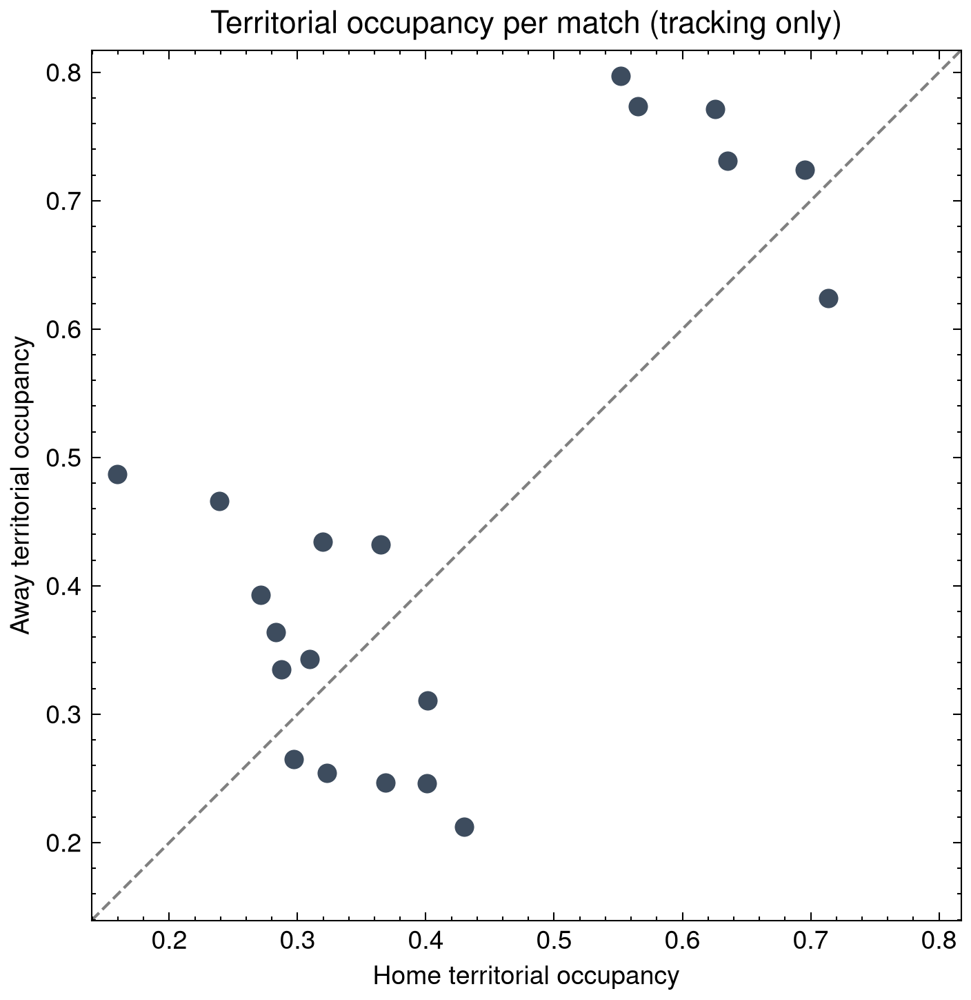

In [7]:
OCCUPANCY_CACHE = os.path.join(DATA_DIR, "occupancy_stats.pkl")

if os.path.exists(OCCUPANCY_CACHE):
    with open(OCCUPANCY_CACHE, "rb") as f:
        occupancy_stats = pickle.load(f)
    print(f"Loaded cached occupancy stats")
else:
    occupancy_stats = []

    for mid in match_ids:
        dataset = skillcorner.load_open_data(
            match_id=mid, coordinates="skillcorner", sample_rate=1 / 5
        )

        home_team = [
            t for t in dataset.metadata.teams if t.ground.value == "home"
        ][0]
        away_team = [
            t for t in dataset.metadata.teams if t.ground.value == "away"
        ][0]

        # Determine attack direction in period 1: if the home team's average
        # x position is negative in early frames, they occupy the left half
        # and attack toward positive x.
        early = dataset.frames[:50]
        home_xs = [
            d.coordinates.x
            for f in early
            for p, d in f.players_data.items()
            if p.team.team_id == home_team.team_id and d.coordinates
        ]
        home_attacks_positive_p1 = np.mean(home_xs) < 0

        home_occ, away_occ = [], []

        for frame in dataset.frames:
            if frame.ball_owning_team is None:
                continue

            period = frame.period.id if frame.period else 1
            if period == 1:
                home_sign = 1 if home_attacks_positive_p1 else -1
            else:
                home_sign = -1 if home_attacks_positive_p1 else 1
            away_sign = -home_sign

            owning_id = frame.ball_owning_team.team_id

            if owning_id == away_team.team_id:
                xs = [
                    d.coordinates.x
                    for p, d in frame.players_data.items()
                    if p.team.team_id == home_team.team_id and d.coordinates
                ]
                if xs:
                    home_occ.append(
                        sum(1 for x in xs if x * home_sign > 0) / len(xs)
                    )

            elif owning_id == home_team.team_id:
                xs = [
                    d.coordinates.x
                    for p, d in frame.players_data.items()
                    if p.team.team_id == away_team.team_id and d.coordinates
                ]
                if xs:
                    away_occ.append(
                        sum(1 for x in xs if x * away_sign > 0) / len(xs)
                    )

        occupancy_stats.append(
            {
                "match_id": mid,
                "home_occupancy": np.mean(home_occ) if home_occ else np.nan,
                "away_occupancy": np.mean(away_occ) if away_occ else np.nan,
            }
        )

        del dataset
        h = occupancy_stats[-1]["home_occupancy"]
        a = occupancy_stats[-1]["away_occupancy"]
        print(f"  {mid}: home={h:.3f}, away={a:.3f}")

    with open(OCCUPANCY_CACHE, "wb") as f:
        pickle.dump(occupancy_stats, f)

occ_df = pd.DataFrame(occupancy_stats)
home_higher = (occ_df["home_occupancy"] > occ_df["away_occupancy"]).sum()
print(f"\nMean territorial occupancy when defending:")
print(f"  Home: {occ_df['home_occupancy'].mean():.3f}  |  Away: {occ_df['away_occupancy'].mean():.3f}")
print(f"  Home higher in {home_higher}/{len(occ_df)} matches")

fig, ax = plt.subplots(figsize=(5, 5))
lo = min(occ_df[["home_occupancy", "away_occupancy"]].min()) - 0.02
hi = max(occ_df[["home_occupancy", "away_occupancy"]].max()) + 0.02
ax.scatter(
    occ_df["home_occupancy"], occ_df["away_occupancy"],
    s=60, c="#3D4C5E", edgecolors="white", zorder=3,
)
ax.plot([lo, hi], [lo, hi], ls="--", c="grey", lw=1, zorder=1)
ax.set_xlabel("Home territorial occupancy")
ax.set_ylabel("Away territorial occupancy")
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal")
ax.set_title("Territorial occupancy per match (tracking only)")
plt.tight_layout()
plt.show()

## Pressing efficiency

### Data vizualisation and exploration

In [8]:
regain_idx = [i + 1 for i, c in enumerate(configs) if c["end_type"] == "regain"]
print(f"Regain chains ({len(regain_idx)}):\n{regain_idx}")
print(f"\nDisruption chains: {sum(1 for c in configs if c['end_type'] == 'disruption')}")

Regain chains (567):
[2, 4, 5, 6, 18, 25, 27, 28, 29, 31, 32, 35, 37, 38, 39, 41, 43, 49, 51, 57, 58, 59, 62, 64, 67, 72, 77, 78, 81, 86, 90, 94, 95, 100, 102, 104, 106, 107, 110, 112, 115, 116, 118, 122, 123, 124, 125, 129, 130, 131, 134, 139, 140, 141, 142, 143, 146, 154, 157, 158, 161, 163, 165, 172, 175, 181, 182, 183, 185, 186, 187, 189, 190, 191, 196, 201, 203, 206, 208, 209, 212, 215, 218, 219, 220, 222, 225, 226, 227, 233, 234, 236, 237, 241, 242, 245, 247, 249, 252, 255, 256, 257, 261, 262, 265, 266, 271, 272, 273, 274, 275, 276, 278, 280, 285, 288, 290, 291, 292, 293, 294, 300, 302, 303, 304, 305, 306, 311, 315, 319, 326, 330, 332, 338, 339, 340, 343, 344, 346, 349, 350, 351, 353, 355, 359, 360, 367, 370, 372, 373, 374, 376, 378, 386, 387, 388, 389, 391, 398, 399, 400, 402, 405, 407, 412, 420, 421, 426, 427, 433, 436, 438, 447, 448, 453, 454, 457, 462, 464, 470, 471, 473, 474, 476, 477, 485, 487, 488, 490, 491, 500, 503, 507, 513, 514, 515, 517, 522, 523, 526, 536, 537, 539, 

python(31627) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(31628) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


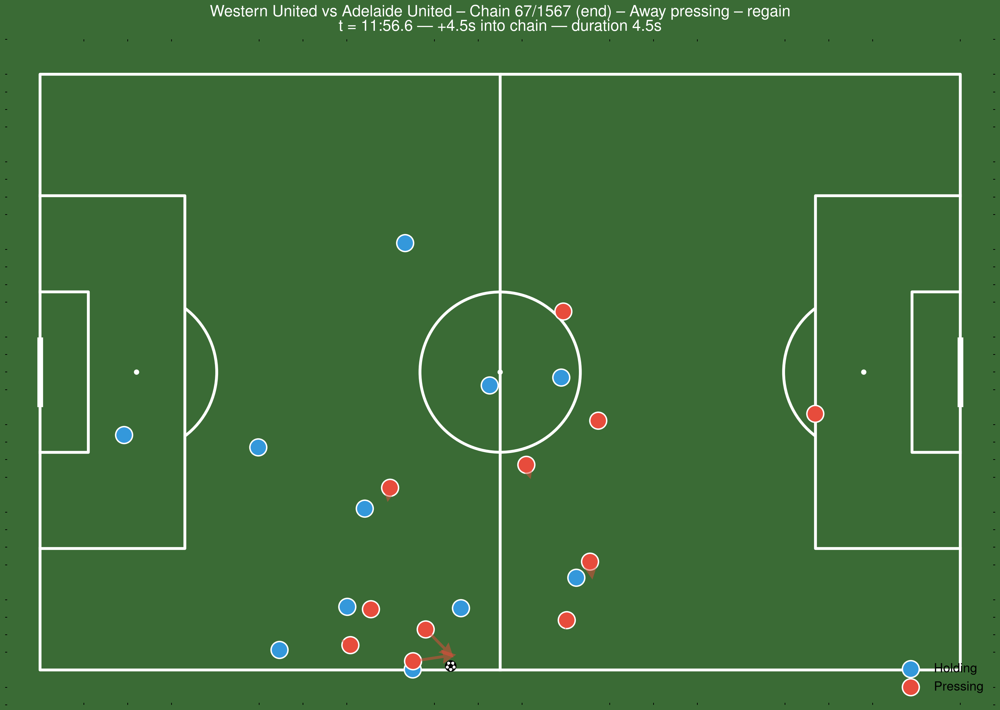

In [57]:
from mplsoccer.soccer.markers import scatter_football, football_hexagon_marker, football_pentagon_marker

CHAIN_INDEX = 67        # 1 to len(configs)
TIMEPOINT = "end"    # "start", "mid", or "end"

c = configs[CHAIN_INDEX - 1]

if TIMEPOINT == "start":
    press, hold, ball = c["pressing"], c["holding"], np.array(c["ball_xy"])
    frame_now = c["frame_start"]
elif TIMEPOINT == "mid":
    press, hold, ball = c["pressing_mid"], c["holding_mid"], np.array(c["ball_xy_mid"])
    frame_now = c["frame_mid"]
else:
    press, hold, ball = c["pressing_end"], c["holding_end"], np.array(c["ball_xy_end"])
    frame_now = c["frame_last"]

press_xy, press_v = press[:, :2], press[:, 2:]
hold_xy = hold[:, :2]

px, py = press_xy[:, 0] + 52.5, press_xy[:, 1] + 34
hx, hy = hold_xy[:, 0] + 52.5, hold_xy[:, 1] + 34
bx, by = ball[0] + 52.5, ball[1] + 34

vx, vy = press_v[:, 0], press_v[:, 1]
max_speed = np.sqrt(vx**2 + vy**2).max()
ARROW_MAX = 5
scale = ARROW_MAX / max_speed if max_speed > 0 else 1

match_info = next(m for m in matches if m["id"] == c["match_id"])
home_name = match_info["home_team"]["short_name"]
away_name = match_info["away_team"]["short_name"]
outcome = c["end_type"] if isinstance(c["end_type"], str) else "unknown"
side = "Home" if c["is_home_pressing"] else "Away"

match_sec = frame_now / FPS
match_min = int(match_sec // 60)
match_s = match_sec % 60
elapsed = (frame_now - c["frame_start"]) / FPS

PITCH_BG = "#3a6b35"

pitch = Pitch(pitch_type="custom", pitch_length=105, pitch_width=68,
              pitch_color=PITCH_BG, line_color="white")
fig, ax = pitch.draw(figsize=(10, 7))
fig.patch.set_facecolor(PITCH_BG)

hold_h = pitch.scatter(hx, hy, ax=ax, s=140, c="#3498db", edgecolors="white", zorder=3)
press_h = pitch.scatter(px, py, ax=ax, s=140, c="#e74c3c", edgecolors="white", zorder=3)
pitch.arrows(px, py, px + vx * scale, py + vy * scale,
             ax=ax, color="#e74c3c", width=2, headwidth=5, zorder=4, alpha=0.5)
scatter_football(bx, by, ax=ax, s=60, c="white", edgecolors="black", zorder=5)

ax.set_title(
    f"{home_name} vs {away_name} -- Chain {CHAIN_INDEX}/{len(configs)} ({TIMEPOINT}) -- "
    f"{side} pressing -- {outcome}\n"
    f"t = {match_min}:{match_s:04.1f}  |  +{elapsed:.1f}s into chain  |  "
    f"duration {c['chain_duration']:.1f}s",
    fontsize=11, color="white",
)
leg = ax.legend(
    [hold_h, press_h],
    ["Holding", "Pressing"],
    loc="lower right", fontsize=9,
    facecolor=PITCH_BG, edgecolor=PITCH_BG,
    labelcolor="black",
)
for text in leg.get_texts():
    text.set_fontweight("bold")
plt.tight_layout()
plt.show()

In [42]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from mplsoccer.soccer.markers import football_hexagon_marker, football_pentagon_marker

CHAIN_INDEX_ANIM = 495
EXTRA_SECONDS = 7
ANIM_DPI = 10

PITCH_BG = "#3a6b35"

TEAM_COLORS = {
    866:  ("#e4002b", "#f2a900"),  # Adelaide United: red / gold
    4177: ("#00205b", "#68b8e5"),  # Auckland FC: navy / sky blue
    1802: ("#f36c21", "#1a1a1a"),  # Brisbane Roar: orange / black
    870:  ("#f7d417", "#003087"),  # CC Mariners: yellow / navy
    1804: ("#1a1a1a", "#c8a64e"),  # Macarthur FC: black / gold
    2380: ("#6caddf", "#1c2c5b"),  # Melbourne City: sky blue / navy
    868:  ("#0e1e45", "#ffffff"),  # Melbourne Victory: navy / white
    1805: ("#c8102e", "#f1be48"),  # Newcastle Jets: red / gold
    871:  ("#5b2d8e", "#f2a900"),  # Perth Glory: purple / gold
    869:  ("#6cace4", "#1a3a6b"),  # Sydney FC: sky blue / navy
    867:  ("#ffcb05", "#1a1a1a"),  # Wellington Phoenix: yellow / black
    2902: ("#e4002b", "#1a1a1a"),  # Western Sydney: red / black
    1803: ("#2d8a4e", "#1a1a1a"),  # Western United: green / black
}

c = configs[CHAIN_INDEX_ANIM - 1]
mid = c["match_id"]
fs, fl = c["frame_start"], c["frame_last"]
fl_ext = fl + int(EXTRA_SECONDS * FPS)

match_info = next(m for m in matches if m["id"] == c["match_id"])
home_name = match_info["home_team"]["short_name"]
away_name = match_info["away_team"]["short_name"]
press_tid = home_team_ids[mid] if c["is_home_pressing"] else match_info["away_team"]["id"]
outcome = c["end_type"] if isinstance(c["end_type"], str) else "unknown"
side_label = "Home" if c["is_home_pressing"] else "Away"

hold_tid = home_team_ids[mid] if not c["is_home_pressing"] else match_info["away_team"]["id"]
press_name = away_name if not c["is_home_pressing"] else home_name
hold_name = home_name if not c["is_home_pressing"] else away_name
press_color, press_edge = TEAM_COLORS.get(press_tid, ("#e74c3c", "#ffffff"))
hold_color, hold_edge = TEAM_COLORS.get(hold_tid, ("#3498db", "#ffffff"))

try:
    _anim_cache
except NameError:
    _anim_cache = {}

if mid not in _anim_cache:
    print(f"Downloading tracking for match {mid} ...")
    _ds = skillcorner.load_open_data(match_id=mid, coordinates="skillcorner")
    _store = {}
    for _f in _ds.frames:
        _pl = {}
        for _p, _pd in _f.players_data.items():
            if _pd.coordinates is not None:
                _pl[_p.player_id] = (
                    _p.team.team_id,
                    _pd.coordinates.x + 52.5,
                    _pd.coordinates.y + 34,
                )
        _bc = _f.ball_coordinates
        _store[_f.frame_id] = {
            "p": _pl,
            "b": (
                (_bc.x + 52.5) if _bc else np.nan,
                (_bc.y + 34) if _bc else np.nan,
                (getattr(_bc, "z", 0.0) or 0.0) if _bc else 0.0,
            ),
        }
    del _ds
    _anim_cache[mid] = _store
    print(f"  {len(_store)} frames cached in memory")

trk = _anim_cache[mid]
fids = sorted(f for f in trk if fs <= f <= fl_ext)
N = len(fids)
chain_end_idx = next((i for i, f in enumerate(fids) if f >= fl), N - 1)
print(f"Chain {CHAIN_INDEX_ANIM}: {N} frames ({chain_end_idx + 1} chain + {N - chain_end_idx - 1} extra)")

anim_frames = []
for i, fid in enumerate(fids):
    rd = trk[fid]
    press, hold = {}, {}
    for pid, (tid, x, y) in rd["p"].items():
        (press if tid == press_tid else hold)[pid] = (x, y)

    press_vel = {}
    if i > 0:
        prev_press = anim_frames[i - 1]["press"]
        for pid, (x, y) in press.items():
            if pid in prev_press:
                px0, py0 = prev_press[pid]
                press_vel[pid] = ((x - px0) * FPS, (y - py0) * FPS)
    anim_frames.append({"press": press, "hold": hold, "ball": rd["b"], "press_vel": press_vel})

pitch = Pitch(pitch_type="custom", pitch_length=105, pitch_width=68,
              pitch_color=PITCH_BG, line_color="white")
fig, ax = pitch.draw(figsize=(10, 7))
fig.set_dpi(ANIM_DPI)
fig.patch.set_facecolor(PITCH_BG)

hold_scat = ax.scatter([], [], s=140, c=hold_color, edgecolors=hold_edge, zorder=3)
press_scat = ax.scatter([], [], s=140, c=press_color, edgecolors=press_edge, zorder=3)
ball_hex = ax.scatter([], [], s=60, c="white", edgecolors="black",
                      linewidths=0.5, marker=football_hexagon_marker, zorder=5)
ball_pent = ax.scatter([], [], s=60, c="black", edgecolors="black",
                       linewidths=0.5, marker=football_pentagon_marker, zorder=5)

ARROW_SCALE = 1
ARROW_WIDTH = 0.004
_arrow_artists = []

leg = ax.legend(
    [hold_scat, press_scat],
    [hold_name + " (holding)", press_name + " (pressing)"],
    loc="upper right", fontsize=9,
    bbox_to_anchor=(1.0, 1.12),
    facecolor=PITCH_BG, edgecolor=PITCH_BG,
    labelcolor="white",
)
for text in leg.get_texts():
    text.set_fontweight("bold")

BALL_S_MIN = 60
BALL_S_MAX = 180
BALL_Z_CAP = 10.0

def _update(i):
    f = anim_frames[i]

    if f["hold"]:
        hxy = np.array(list(f["hold"].values()))
        hold_scat.set_offsets(hxy)
    else:
        hold_scat.set_offsets(np.empty((0, 2)))

    if f["press"]:
        pxy = np.array(list(f["press"].values()))
        press_scat.set_offsets(pxy)
    else:
        press_scat.set_offsets(np.empty((0, 2)))

    bx, by, bz = f["ball"]
    ball_hex.set_offsets([[bx, by]])
    ball_pent.set_offsets([[bx, by]])
    z_frac = min(max(bz, 0.0), BALL_Z_CAP) / BALL_Z_CAP
    ball_s = BALL_S_MIN + (BALL_S_MAX - BALL_S_MIN) * z_frac
    ball_hex.set_sizes([ball_s])
    ball_pent.set_sizes([ball_s])

    for a in _arrow_artists:
        a.remove()
    _arrow_artists.clear()

    pv = f["press_vel"]
    if f["press"] and pv:
        pids_with_vel = [pid for pid in f["press"] if pid in pv]
        if pids_with_vel:
            qx = np.array([f["press"][pid][0] for pid in pids_with_vel])
            qy = np.array([f["press"][pid][1] for pid in pids_with_vel])
            qu = np.array([pv[pid][0] for pid in pids_with_vel]) / ARROW_SCALE
            qv = np.array([pv[pid][1] for pid in pids_with_vel]) / ARROW_SCALE
            q = ax.quiver(qx, qy, qu, qv, color=press_color, alpha=0.5,
                          scale=1, scale_units="xy", angles="xy",
                          width=ARROW_WIDTH, headwidth=4, headlength=5, zorder=4)
            _arrow_artists.append(q)

    fid = fids[i]
    t_s = fid / FPS
    elapsed = (fid - fs) / FPS
    after = (fid - fl) / FPS
    phase = f"  [+{after:.1f}s after chain end]" if fid > fl else ""
    ax.set_title(
        f"{home_name} vs {away_name}; pressing sequence",
        fontsize=13, color="white", fontweight="bold",
    )
    return hold_scat, press_scat, ball_hex, ball_pent

# --- Title card: frozen first frame with overlay text ---
N_TITLE_FRAMES = 20  # 2 seconds at 100ms interval
title_text = ax.text(
    52.5, 34, "Pressing effectiveness analysis\nSkillCorner tracking data",
    fontsize=16, fontweight="bold", color="white",
    ha="center", va="center", zorder=10,
    bbox=dict(boxstyle="round,pad=0.8", facecolor=PITCH_BG, alpha=0.85, edgecolor="white", linewidth=1.5),
)

def _update_with_title(i):
    if i < N_TITLE_FRAMES:
        title_text.set_visible(True)
        return _update(0)
    else:
        title_text.set_visible(False)
        return _update(i - N_TITLE_FRAMES)

N_TOTAL = N + N_TITLE_FRAMES
print(f"Rendering {N_TOTAL} frames ({N_TITLE_FRAMES} title + {N} animation) at {ANIM_DPI} DPI ...")
anim = FuncAnimation(fig, _update_with_title, frames=N_TOTAL, interval=100, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())

  46297 frames cached in memory
Chain 495: 121 frames (51 chain + 70 extra)
Rendering 141 frames (20 title + 121 animation) at 10 DPI ...


Up to now, we've asked about the differential aggressiveness of home and away teams in pressing behavior. But is pressing aggressiveness effective? If not, what makes a pressing effective? Is it some measure of the "intelligence" of the pressing strategy? Is it a combination of pressing aggressiveness and pressing intelligence?

Below, we address these questions in two different ways. First, we construct features that summarize information about the aggressiveness and geometry of a pressing strategy. We measure which of these features predicts best the success or failure of a pressure attempt. Second, we use a deep learning approach where we try to determine whether the positions of the 20 outfield players can better predict the outcome of a pressing effort, beyond the summary features built in the logistic regression.

### Logistic regression

#### Feature construction

In [ ]:
known = [c for c in configs if c["end_type"] in ("regain", "disruption")]
print(f"Chains with known outcome: {len(known)} / {len(configs)}")
print(f"  Regain:     {sum(c['label'] == 1 for c in known)}")
print(f"  Disruption: {sum(c['label'] == 0 for c in known)}")

LOCAL_RADIUS = 15   # meters, for local density and passing options
LANE_WIDTH = 2      # meters, perpendicular distance to count as blocking a passing lane
K_NEAREST = 3       # number of nearest pressers for closing speed

TIMEPOINT = "end"   # "mid" or "end"

features = []
for c in known:
    press_xy = c[f"pressing_{TIMEPOINT}"][:, :2]
    press_v  = c[f"pressing_{TIMEPOINT}"][:, 2:]
    hold_xy  = c[f"holding_{TIMEPOINT}"][:, :2]
    ball     = np.array(c[f"ball_xy_{TIMEPOINT}"])

    # --- Closing speed of K nearest pressers ---
    to_ball = ball - press_xy
    dist_to_ball = np.linalg.norm(to_ball, axis=1)
    unit_to_ball = to_ball / dist_to_ball.clip(1e-6)[:, None]
    closing = np.sum(press_v * unit_to_ball, axis=1)
    nearest_k = np.argsort(dist_to_ball)[:K_NEAREST]
    closing_speed_nearest = np.mean(closing[nearest_k])

    # --- Local holding density (holders within LOCAL_RADIUS of ball) ---
    hold_dist_to_ball = np.linalg.norm(hold_xy - ball, axis=1)
    local_hold_density = np.sum(hold_dist_to_ball < LOCAL_RADIUS)

    # --- Free passing options (angle-aware) ---
    # A holder near the ball is "free" if no presser sits on the passing lane
    # between ball and that holder (within LANE_WIDTH perpendicular distance).
    local_mask = hold_dist_to_ball < LOCAL_RADIUS
    local_holders = hold_xy[local_mask]
    if len(local_holders) > 0:
        free_count = 0
        for receiver in local_holders:
            lane_vec = receiver - ball
            lane_len = np.linalg.norm(lane_vec)
            if lane_len < 1.0:
                continue  # likely the ball carrier
            lane_unit = lane_vec / lane_len

            # Project each presser onto the ball->receiver lane
            to_presser = press_xy - ball
            t = np.dot(to_presser, lane_unit) / lane_len  # 0 = ball, 1 = receiver
            proj = ball + t[:, None] * lane_vec
            d_perp = np.linalg.norm(press_xy - proj, axis=1)

            # Blocked if any presser is between ball and receiver AND close to the lane
            if not np.any((t > 0) & (t < 1) & (d_perp < LANE_WIDTH)):
                free_count += 1
        free_options = free_count
    else:
        free_options = 0

    # --- Numerical superiority near ball ---
    press_near = np.sum(dist_to_ball < LOCAL_RADIUS)
    num_superiority = press_near - local_hold_density

    # --- Boundary distances (SkillCorner coords: center = 0,0) ---
    dist_sideline = min(ball[1] + 34, 34 - ball[1])
    dist_goalline = min(ball[0] + 52.5, 52.5 - ball[0])

    features.append({
        "closing_speed_nearest": closing_speed_nearest,
        "local_hold_density": local_hold_density,
        "free_options": free_options,
        "num_superiority": num_superiority,
        "dist_sideline": dist_sideline,
        "dist_goalline": dist_goalline,
        "chain_duration": c["chain_duration"],
        "is_home": int(c["is_home_pressing"]),
        "label": c["label"],
    })

feat_df = pd.DataFrame(features)
feat_df["is_home_x_closing"] = feat_df["is_home"] * feat_df["closing_speed_nearest"]
feat_df["closing_x_num_sup"] = feat_df["closing_speed_nearest"] * feat_df["num_superiority"]
feat_df["closing_x_goalline"] = feat_df["closing_speed_nearest"] * feat_df["dist_goalline"]
feat_df["free_opt_x_sideline"] = feat_df["free_options"] * feat_df["dist_sideline"]
feat_df["num_sup_x_free_opt"] = feat_df["num_superiority"] * feat_df["free_options"]
feat_df["is_home_x_num_sup"] = feat_df["is_home"] * feat_df["num_superiority"]

print(f"\nFeatures extracted at: {TIMEPOINT}-chain")
print(f"Feature matrix: {feat_df.shape[0]} rows x {feat_df.shape[1] - 1} features + label")
feat_df.describe().round(2)

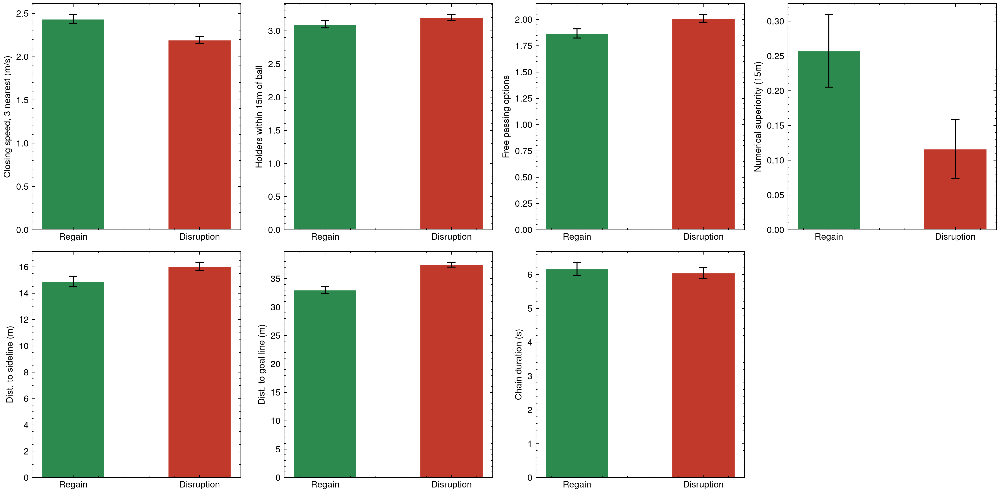

In [53]:
cont_features = [
    ("closing_speed_nearest", "Closing speed, 3 nearest (m/s)"),
    ("local_hold_density", "Holders within 15m of ball"),
    ("free_options", "Free passing options"),
    ("num_superiority", "Numerical superiority (15m)"),
    ("dist_sideline", "Dist. to sideline (m)"),
    ("dist_goalline", "Dist. to goal line (m)"),
    ("chain_duration", "Chain duration (s)"),
]

regain = feat_df[feat_df["label"] == 1]
disrupt = feat_df[feat_df["label"] == 0]

ncols = 4
nrows = (len(cont_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
axes = axes.flatten()

for ax, (col, label) in zip(axes, cont_features):
    means = [regain[col].mean(), disrupt[col].mean()]
    ses = [
        regain[col].std() / np.sqrt(len(regain)),
        disrupt[col].std() / np.sqrt(len(disrupt)),
    ]
    bars = ax.bar(
        [0, 1], means, yerr=ses, capsize=4,
        color=["#2d8a4e", "#c0392b"], width=0.5, edgecolor="white",
    )
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Regain", "Disruption"])
    ax.set_ylabel(label)

for ax in axes[len(cont_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

#### Training the model

In [ ]:
from sklearn.model_selection import train_test_split

feature_cols = [
    "closing_speed_nearest", "local_hold_density", "free_options",
    "num_superiority", "dist_sideline", "dist_goalline",
    "chain_duration",
    "is_home", "is_home_x_closing",
    "closing_x_num_sup", "closing_x_goalline",
    "is_home_x_num_sup",
    "free_opt_x_sideline", "num_sup_x_free_opt",
]

X = feat_df[feature_cols].values
y = feat_df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Train: {len(X_train)} ({y_train.sum()} regain, {len(y_train) - y_train.sum()} disruption)")
print(f"Test:  {len(X_test)} ({y_test.sum()} regain, {len(y_test) - y_test.sum()} disruption)")

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_s, y_train)

y_prob = clf.predict_proba(X_test_s)[:, 1]
auc = roc_auc_score(y_test, y_prob)
ap = average_precision_score(y_test, y_prob)
acc = clf.score(X_test_s, y_test)

print(f"\nTest accuracy: {acc:.3f}")
print(f"Test AUC:      {auc:.3f}")
print(f"Test AP:       {ap:.3f}")

print("\nCoefficients:")
for name, coef in zip(feature_cols, clf.coef_[0]):
    print(f"  {name:>25s}: {coef:+.3f}")
print(f"  {'intercept':>25s}: {clf.intercept_[0]:+.3f}")

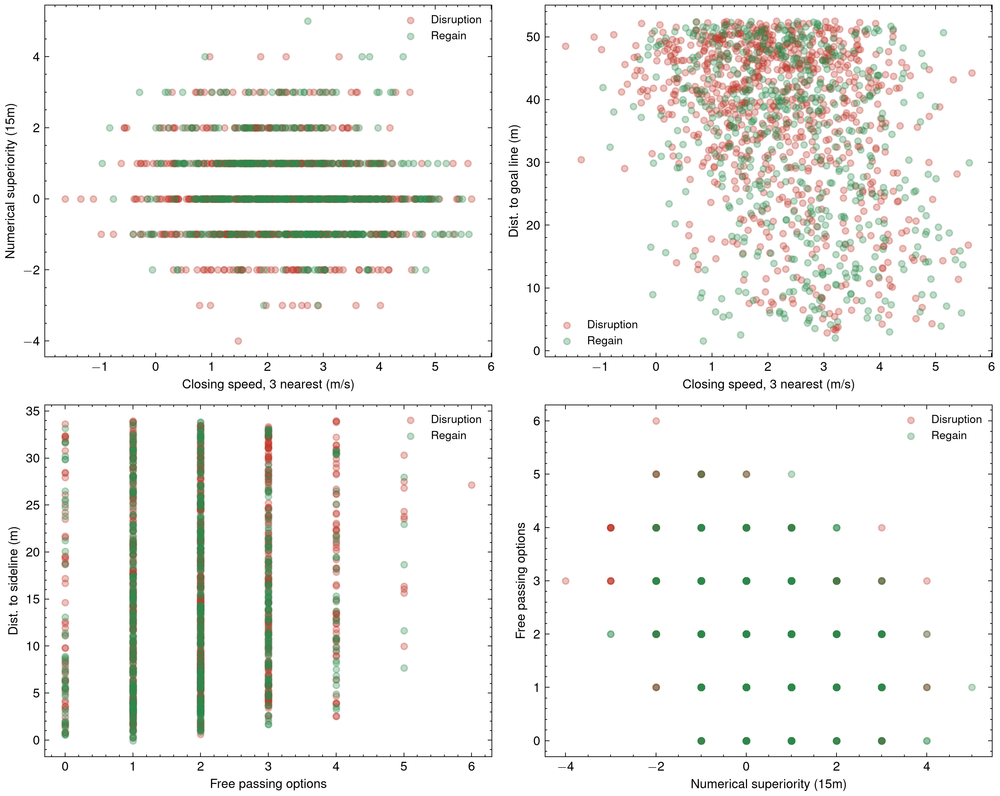

In [14]:
interactions = [
    ("closing_speed_nearest", "num_superiority",
     "Closing speed, 3 nearest (m/s)", "Numerical superiority (15m)"),
    ("closing_speed_nearest", "dist_goalline",
     "Closing speed, 3 nearest (m/s)", "Dist. to goal line (m)"),
    ("free_options", "dist_sideline",
     "Free passing options", "Dist. to sideline (m)"),
    ("num_superiority", "free_options",
     "Numerical superiority (15m)", "Free passing options"),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (col_x, col_y, lbl_x, lbl_y) in zip(axes.flat, interactions):
    mask_r = feat_df["label"] == 1
    ax.scatter(feat_df.loc[~mask_r, col_x], feat_df.loc[~mask_r, col_y],
               c="#c0392b", alpha=0.3, s=20, label="Disruption")
    ax.scatter(feat_df.loc[mask_r, col_x], feat_df.loc[mask_r, col_y],
               c="#2d8a4e", alpha=0.3, s=20, label="Regain")
    ax.set_xlabel(lbl_x)
    ax.set_ylabel(lbl_y)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Deep learning

The logistic regression above relies on hand-crafted summary features (closing speed, numerical superiority, boundary distances) extracted from a single snapshot of each pressing chain. This forces us to decide in advance which aspects of the spatial configuration matter. A deep learning model can instead ingest the raw positions and velocities of all 20 outfield players and learn its own summary.

A pressing configuration is a *set* of players: there is no natural ordering among the ten players on one side. Swapping player A and player B in the input should not change the prediction. Architectures like DeepSets (Zaheer et al., 2017) enforce this *permutation invariance* by processing each player independently through a shared network, aggregating with a symmetric operation (sum or mean), and post-processing the aggregate.

Permutation invariance is a simplification. In reality, *who* occupies a given position matters: a center-back caught 70 meters up the pitch exposes the team far more than a striker at the same location. If we had player-role labels (defender, midfielder, forward), we could attach them as per-player features; the shared network would then learn to treat them differently, while still being invariant to the ordering of players *within* the same role. With consistent player identities across matches and enough data per player, the network could even learn individual pressing profiles. Our dataset (20 matches, ~1500 chains) is too small for player-level embeddings, and we do not include role labels here, so we treat all players on a side as interchangeable. The model's focus is therefore on the collective geometry and closing speed of the press — which aligns with the aggression dimensions (frequency and velocity) that motivate this analysis.

In [15]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# --- Build per-player feature tensors from the cached configs ---
# Each player is represented by 8 features:
#   x, y         — position on the pitch (SkillCorner coords, centered at 0,0)
#   vx, vy       — velocity components (m/s, from Savitzky-Golay smoothing)
#   is_pressing  — 1 if on pressing team, 0 if on holding team
#   dist_to_ball — Euclidean distance to the ball (meters)
#   ball_abs_x   — |ball_x|, distance from halfway line (0–52.5m), broadcast
#   ball_abs_y   — |ball_y|, distance from pitch center width (0–34m), broadcast
#
# Ball position uses absolute values so that symmetric pitch locations
# (near either goal line, near either sideline) are encoded identically.
# Player positions keep their raw signed coordinates.
#
# Players are padded to 11 per side (22 total per chain).
# A binary mask tracks which slots hold real players vs padding.

known_dl = [c for c in configs if c["end_type"] in ("regain", "disruption")]

MAX_PER_SIDE = 11
IN_DIM = 8

X_all = np.zeros((len(known_dl), 2 * MAX_PER_SIDE, IN_DIM), dtype=np.float32)
M_all = np.zeros((len(known_dl), 2 * MAX_PER_SIDE), dtype=np.float32)
y_all = np.zeros(len(known_dl), dtype=np.float32)

for i, c in enumerate(known_dl):
    press = c["pressing_end"]           # (n_press, 4): x, y, vx, vy
    hold  = c["holding_end"]            # (n_hold, 4):  x, y, vx, vy
    ball  = np.array(c["ball_xy_end"])
    ball_abs_x = abs(ball[0])           # distance from halfway line (0–52.5)
    ball_abs_y = abs(ball[1])           # distance from pitch center width (0–34)

    # First 11 slots = pressing team, next 11 = holding team
    for players, is_press, offset in [
        (press, 1.0, 0),
        (hold,  0.0, MAX_PER_SIDE),
    ]:
        n = min(len(players), MAX_PER_SIDE)
        xy = players[:n, :2]
        v  = players[:n, 2:]
        dist = np.linalg.norm(xy - ball, axis=1)
        X_all[i, offset:offset+n, 0:2] = xy
        X_all[i, offset:offset+n, 2:4] = v
        X_all[i, offset:offset+n, 4]   = is_press
        X_all[i, offset:offset+n, 5]   = dist
        X_all[i, offset:offset+n, 6]   = ball_abs_x
        X_all[i, offset:offset+n, 7]   = ball_abs_y
        M_all[i, offset:offset+n] = 1.0

    y_all[i] = c["label"]

# --- Same 80/20 stratified split as the logistic regression (random_state=42) ---
idx = np.arange(len(known_dl))
train_idx, test_idx = train_test_split(
    idx, test_size=0.2, stratify=y_all, random_state=42
)

# --- Standardize continuous features using training-set statistics only ---
# Column 4 (is_pressing) is binary and left as-is.
# Statistics are computed over real players only (mask == 1), not padding.
cont_cols = [0, 1, 2, 3, 5, 6, 7]
real_train = X_all[train_idx][M_all[train_idx].astype(bool)]
feat_mean = real_train[:, cont_cols].mean(axis=0)
feat_std  = real_train[:, cont_cols].std(axis=0) + 1e-8
X_all[:, :, cont_cols] = (X_all[:, :, cont_cols] - feat_mean) / feat_std
# Padded entries get non-zero values after normalization, but the model
# masks them out before aggregation so they don't affect predictions.

# --- PyTorch DataLoaders ---
train_ds = TensorDataset(
    torch.from_numpy(X_all[train_idx]),
    torch.from_numpy(M_all[train_idx]),
    torch.from_numpy(y_all[train_idx]),
)
test_ds = TensorDataset(
    torch.from_numpy(X_all[test_idx]),
    torch.from_numpy(M_all[test_idx]),
    torch.from_numpy(y_all[test_idx]),
)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_ds, batch_size=len(test_ds))

print(f"Tensor shapes: X {X_all.shape}, masks {M_all.shape}")
print(f"Train: {len(train_ds)} ({int(y_all[train_idx].sum())} regain, "
      f"{len(train_ds) - int(y_all[train_idx].sum())} disruption)")
print(f"Test:  {len(test_ds)} ({int(y_all[test_idx].sum())} regain, "
      f"{len(test_ds) - int(y_all[test_idx].sum())} disruption)")

Tensor shapes: X (1410, 22, 8), masks (1410, 22)
Train: 1128 (454 regain, 674 disruption)
Test:  282 (113 regain, 169 disruption)


In [16]:
# --- DeepSets architecture ---
# phi:  a shared MLP applied independently to each player's 8-dim feature vector.
#        It maps each player to a 64-dim embedding.
# pool: sum over all (non-padded) player embeddings — this is the step that
#        enforces permutation invariance.
# rho:  a small MLP that maps the 64-dim aggregate to a single logit
#        (P(regain) after sigmoid).

class DeepSetsClassifier(nn.Module):
    def __init__(self, in_dim=8, phi_dim=64, rho_dim=32):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(in_dim, phi_dim),
            nn.ReLU(),
            nn.Linear(phi_dim, phi_dim),
            nn.ReLU(),
            nn.Linear(phi_dim, phi_dim),
        )
        self.rho = nn.Sequential(
            nn.Linear(phi_dim, rho_dim),
            nn.ReLU(),
            nn.Linear(rho_dim, 1),
        )

    def forward(self, x, mask):
        # x:    (batch, 22, 8)  — player features (pressing + holding, padded)
        # mask: (batch, 22)     — 1 for real players, 0 for padding
        h = self.phi(x)                 # (batch, 22, phi_dim) — per-player embeddings
        h = h * mask.unsqueeze(-1)      # zero out padded players before summing
        h = h.sum(dim=1)                # (batch, phi_dim) — the set representation
        return self.rho(h).squeeze(-1)  # (batch,) — logits


# --- Training loop ---
torch.manual_seed(42)
model = DeepSetsClassifier(in_dim=IN_DIM, phi_dim=64, rho_dim=32)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.BCEWithLogitsLoss()

N_EPOCHS = 150
history = {"train_loss": [], "test_loss": [], "test_auc": []}
best_auc = 0.0
best_state = None

for epoch in range(1, N_EPOCHS + 1):
    # Training pass
    model.train()
    epoch_loss = 0.0
    for xb, mb, yb in train_loader:
        logits = model(xb, mb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(yb)
    history["train_loss"].append(epoch_loss / len(train_ds))

    # Evaluation pass
    model.eval()
    with torch.no_grad():
        xt, mt, yt = next(iter(test_loader))
        test_logits = model(xt, mt)
        test_loss = loss_fn(test_logits, yt).item()
        test_probs = torch.sigmoid(test_logits).numpy()
        epoch_auc = roc_auc_score(yt.numpy(), test_probs)

    history["test_loss"].append(test_loss)
    history["test_auc"].append(epoch_auc)

    # Keep the best model by test AUC
    if epoch_auc > best_auc:
        best_auc = epoch_auc
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

    if epoch % 25 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} — train loss {history['train_loss'][-1]:.4f}  "
              f"test loss {test_loss:.4f}  test AUC {epoch_auc:.3f}")

# Restore the best model
model.load_state_dict(best_state)
print(f"\nBest test AUC: {best_auc:.3f} "
      f"(epoch {np.argmax(history['test_auc']) + 1})")

Epoch   1 — train loss 0.6708  test loss 0.6668  test AUC 0.632


Epoch  25 — train loss 0.5949  test loss 0.6598  test AUC 0.636


Epoch  50 — train loss 0.5434  test loss 0.7203  test AUC 0.604


Epoch  75 — train loss 0.4887  test loss 0.8044  test AUC 0.593


Epoch 100 — train loss 0.4210  test loss 0.8738  test AUC 0.580


Epoch 125 — train loss 0.3267  test loss 1.0806  test AUC 0.588


Epoch 150 — train loss 0.2550  test loss 1.3356  test AUC 0.542

Best test AUC: 0.649 (epoch 18)


Model comparison (same test set, same split):

  Model                     Accuracy     AUC      AP
  ------------------------- --------  ------  ------
  Logistic regression          0.635   0.654   0.522
  DeepSets                     0.656   0.649   0.539


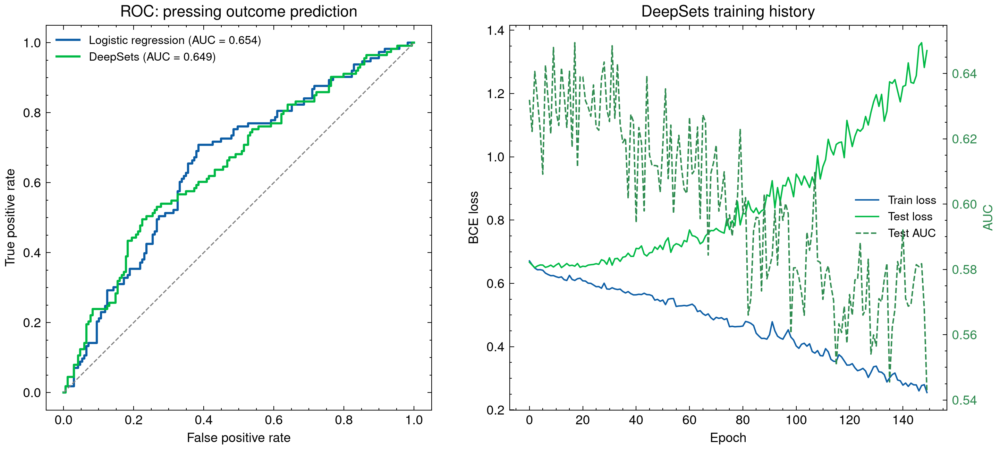

In [17]:
from sklearn.metrics import roc_curve

# --- Final metrics on the best model ---
model.eval()
with torch.no_grad():
    xt, mt, yt = next(iter(test_loader))
    dl_probs = torch.sigmoid(model(xt, mt)).numpy()
    dl_labels = yt.numpy()

dl_auc = roc_auc_score(dl_labels, dl_probs)
dl_ap  = average_precision_score(dl_labels, dl_probs)
dl_acc = ((dl_probs > 0.5) == dl_labels).mean()

print("Model comparison (same test set, same split):\n")
print(f"  {'Model':25s} {'Accuracy':>8s}  {'AUC':>6s}  {'AP':>6s}")
print(f"  {'-'*25} {'-'*8}  {'-'*6}  {'-'*6}")
print(f"  {'Logistic regression':25s} {acc:8.3f}  {auc:6.3f}  {ap:6.3f}")
print(f"  {'DeepSets':25s} {dl_acc:8.3f}  {dl_auc:6.3f}  {dl_ap:6.3f}")

# --- ROC comparison + training curves ---
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)
fpr_dl, tpr_dl, _ = roc_curve(dl_labels, dl_probs)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Left panel: ROC curves for both models
ax = axes[0]
ax.plot(fpr_lr, tpr_lr, lw=1.5, label=f"Logistic regression (AUC = {auc:.3f})")
ax.plot(fpr_dl, tpr_dl, lw=1.5, label=f"DeepSets (AUC = {dl_auc:.3f})")
ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=0.8)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC: pressing outcome prediction")
ax.legend(fontsize=8)
ax.set_aspect("equal")

# Right panel: training history (loss + AUC over epochs)
ax = axes[1]
ax.plot(history["train_loss"], label="Train loss", lw=1)
ax.plot(history["test_loss"], label="Test loss", lw=1)
ax2 = ax.twinx()
ax2.plot(history["test_auc"], color="#2d8a4e", ls="--", lw=1, label="Test AUC")
ax.set_xlabel("Epoch")
ax.set_ylabel("BCE loss")
ax2.set_ylabel("AUC", color="#2d8a4e")
ax2.tick_params(axis="y", labelcolor="#2d8a4e")
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc="center right")
ax.set_title("DeepSets training history")

plt.tight_layout()
plt.show()

#### Temporal extension

The snapshot DeepSets model sees only the spatial configuration at a single moment (chain end). A pressing chain, however, unfolds over several seconds: the positions and velocities of all players evolve as the press develops. To capture this temporal dimension without inflating parameters, we sample T=5 evenly spaced keyframes across each chain. Each keyframe averages over a small window (scaled to 10% of the chain duration, 1–5 frames) to smooth out tracking noise and player visibility flicker. The per-keyframe DeepSets encoder produces a scene embedding at each timepoint; a lightweight 1D convolution then summarizes how the scene changed over the course of the press.

In [18]:
T_KEYFRAMES = 5
TEMPORAL_CACHE = os.path.join(DATA_DIR, "pressing_temporal.pkl")

if os.path.exists(TEMPORAL_CACHE):
    with open(TEMPORAL_CACHE, "rb") as f:
        temporal_configs = pickle.load(f)
    print(f"Loaded {len(temporal_configs)} cached temporal configurations from {TEMPORAL_CACHE}")
else:
    temporal_configs = []

    known_configs = [c for c in configs if c["end_type"] in ("regain", "disruption")]
    by_match = {}
    for c in known_configs:
        by_match.setdefault(c["match_id"], []).append(c)

    for mid, match_cfgs in by_match.items():
        # Resolve team IDs from SkillCorner tracking data
        dataset = skillcorner.load_open_data(match_id=mid, coordinates="skillcorner")
        team_ids_in_match = set()
        for frame in dataset.frames[:50]:
            for player, _ in frame.players_data.items():
                team_ids_in_match.add(player.team.team_id)
                if len(team_ids_in_match) == 2:
                    break
            if len(team_ids_in_match) == 2:
                break
        htid = home_team_ids[mid]
        away_tids = team_ids_in_match - {htid}
        atid = away_tids.pop() if away_tids else None

        # Plan keyframes and windows for every config in this match
        all_needed = set()
        plans = []
        for c in match_cfgs:
            fs, fl = int(c["frame_start"]), int(c["frame_last"])
            n_frames = fl - fs + 1
            kf_targets = np.round(np.linspace(fs, fl, T_KEYFRAMES)).astype(int)
            half_w = max(0, min(2, round(0.1 * n_frames / 2)))

            windows = []
            for kf in kf_targets:
                wf = list(range(max(fs, kf - half_w), min(fl, kf + half_w) + 1))
                windows.append(wf)
                all_needed.update(wf)
            pressing_tid = htid if c["is_home_pressing"] else atid
            plans.append((c, windows, pressing_tid))

        # Expand ±3 for Savitzky-Golay velocity computation
        expanded = set()
        for f in all_needed:
            expanded.update(range(f - 3, f + 4))

        rows = []
        for frame in dataset.frames:
            if frame.frame_id not in expanded:
                continue
            for player, pdata in frame.players_data.items():
                if pdata.coordinates is None:
                    continue
                rows.append({
                    "frame_id": frame.frame_id,
                    "player_id": player.player_id,
                    "team_id": player.team.team_id,
                    "x": pdata.coordinates.x,
                    "y": pdata.coordinates.y,
                    "ball_x": frame.ball_coordinates.x if frame.ball_coordinates else np.nan,
                    "ball_y": frame.ball_coordinates.y if frame.ball_coordinates else np.nan,
                })
        del dataset

        if not rows:
            print(f"  {mid}: no tracking frames matched")
            continue

        pos = pd.DataFrame(rows).sort_values(["player_id", "frame_id"]).reset_index(drop=True)

        # Compute Savitzky-Golay velocities per player (no groupby.apply)
        pos["vx"] = np.nan
        pos["vy"] = np.nan
        for pid in pos["player_id"].unique():
            mask = (pos["player_id"] == pid).values
            x_vals = pos.loc[mask, "x"].values
            y_vals = pos.loc[mask, "y"].values
            frames = pos.loc[mask, "frame_id"].values
            gaps = np.diff(frames, prepend=frames[0] - 1)
            block_ids = np.cumsum(gaps != 1)
            vx = np.full(mask.sum(), np.nan)
            vy = np.full(mask.sum(), np.nan)
            for b_val in np.unique(block_ids):
                bm = block_ids == b_val
                n = bm.sum()
                if n >= SAVGOL_WINDOW:
                    w = SAVGOL_WINDOW
                elif n >= 3:
                    w = n if n % 2 == 1 else n - 1
                else:
                    vx[bm] = np.concatenate([[np.nan], np.diff(x_vals[bm])]) * FPS
                    vy[bm] = np.concatenate([[np.nan], np.diff(y_vals[bm])]) * FPS
                    continue
                vx[bm] = savgol_filter(x_vals[bm], w, SAVGOL_POLY, deriv=1, delta=1/FPS)
                vy[bm] = savgol_filter(y_vals[bm], w, SAVGOL_POLY, deriv=1, delta=1/FPS)
            pos.loc[mask, "vx"] = vx
            pos.loc[mask, "vy"] = vy

        n_ok = 0
        for c, windows, pressing_tid in plans:
            kf_data = []
            ok = True

            for wf in windows:
                wdata = pos[pos["frame_id"].isin(wf)]
                pw = wdata[wdata["team_id"] == pressing_tid]
                hw = wdata[wdata["team_id"] != pressing_tid]

                # Average per player across window frames
                pa = pw.groupby("player_id")[["x", "y", "vx", "vy"]].mean()
                ha = hw.groupby("player_id")[["x", "y", "vx", "vy"]].mean()

                if len(pa) < 8 or len(ha) < 8:
                    ok = False
                    break

                bx = wdata["ball_x"].dropna().mean()
                by = wdata["ball_y"].dropna().mean()
                if np.isnan(bx) or np.isnan(by):
                    ok = False
                    break

                kf_data.append({
                    "pressing": pa.values.astype(np.float32),
                    "holding": ha.values.astype(np.float32),
                    "ball_xy": [float(bx), float(by)],
                })

            if not ok:
                continue

            temporal_configs.append({
                "match_id": mid,
                "is_home_pressing": bool(c["is_home_pressing"]),
                "label": int(c["label"]),
                "end_type": c["end_type"],
                "frame_start": int(c["frame_start"]),
                "frame_last": int(c["frame_last"]),
                "chain_duration": (c["frame_last"] - c["frame_start"]) / FPS,
                "keyframes": kf_data,
            })
            n_ok += 1

        del pos
        print(f"  {mid}: {n_ok}/{len(match_cfgs)} temporal configs extracted")

    with open(TEMPORAL_CACHE, "wb") as f:
        pickle.dump(temporal_configs, f)
    print(f"\nSaved {len(temporal_configs)} temporal configurations to {TEMPORAL_CACHE}")

# --- Filter to known outcomes and build tensors ---
temporal_known = [c for c in temporal_configs if c["end_type"] in ("regain", "disruption")]

MAX_PER_SIDE = 11
IN_DIM_T = 8

Xt_all = np.zeros((len(temporal_known), T_KEYFRAMES, 2 * MAX_PER_SIDE, IN_DIM_T), dtype=np.float32)
Mt_all = np.zeros((len(temporal_known), T_KEYFRAMES, 2 * MAX_PER_SIDE), dtype=np.float32)
yt_all = np.zeros(len(temporal_known), dtype=np.float32)

for i, c in enumerate(temporal_known):
    for t, kf in enumerate(c["keyframes"]):
        press = kf["pressing"]
        hold = kf["holding"]
        ball = np.array(kf["ball_xy"])
        ball_abs_x = abs(ball[0])
        ball_abs_y = abs(ball[1])

        for players, is_press, offset in [
            (press, 1.0, 0),
            (hold, 0.0, MAX_PER_SIDE),
        ]:
            n = min(len(players), MAX_PER_SIDE)
            xy = players[:n, :2]
            v = players[:n, 2:]
            dist = np.linalg.norm(xy - ball, axis=1)
            Xt_all[i, t, offset:offset+n, 0:2] = xy
            Xt_all[i, t, offset:offset+n, 2:4] = v
            Xt_all[i, t, offset:offset+n, 4] = is_press
            Xt_all[i, t, offset:offset+n, 5] = dist
            Xt_all[i, t, offset:offset+n, 6] = ball_abs_x
            Xt_all[i, t, offset:offset+n, 7] = ball_abs_y
            Mt_all[i, t, offset:offset+n] = 1.0

    yt_all[i] = c["label"]

# --- Same stratified split (random_state=42) ---
idx_t = np.arange(len(temporal_known))
train_idx_t, test_idx_t = train_test_split(
    idx_t, test_size=0.2, stratify=yt_all, random_state=42
)

# --- Standardize continuous features (training set only) ---
cont_cols_t = [0, 1, 2, 3, 5, 6, 7]
real_train_t = Xt_all[train_idx_t][Mt_all[train_idx_t].astype(bool)]
feat_mean_t = real_train_t[:, cont_cols_t].mean(axis=0)
feat_std_t = real_train_t[:, cont_cols_t].std(axis=0) + 1e-8
Xt_all[:, :, :, cont_cols_t] = (Xt_all[:, :, :, cont_cols_t] - feat_mean_t) / feat_std_t

# --- DataLoaders ---
train_ds_t = TensorDataset(
    torch.from_numpy(Xt_all[train_idx_t]),
    torch.from_numpy(Mt_all[train_idx_t]),
    torch.from_numpy(yt_all[train_idx_t]),
)
test_ds_t = TensorDataset(
    torch.from_numpy(Xt_all[test_idx_t]),
    torch.from_numpy(Mt_all[test_idx_t]),
    torch.from_numpy(yt_all[test_idx_t]),
)
train_loader_t = DataLoader(train_ds_t, batch_size=64, shuffle=True)
test_loader_t = DataLoader(test_ds_t, batch_size=len(test_ds_t))

print(f"\nTemporal tensor shapes: X {Xt_all.shape}, masks {Mt_all.shape}")
print(f"Train: {len(train_ds_t)} ({int(yt_all[train_idx_t].sum())} regain, "
      f"{len(train_ds_t) - int(yt_all[train_idx_t].sum())} disruption)")
print(f"Test:  {len(test_ds_t)} ({int(yt_all[test_idx_t].sum())} regain, "
      f"{len(test_ds_t) - int(yt_all[test_idx_t].sum())} disruption)")

  2017461: 50/50 temporal configs extracted


  2016236: 71/71 temporal configs extracted


  2015213: 77/77 temporal configs extracted


  2013725: 66/66 temporal configs extracted


  2011166: 53/53 temporal configs extracted


  2010085: 62/62 temporal configs extracted


... (10 outputs left out)

  1925299: 72/72 temporal configs extracted


  1899585: 70/70 temporal configs extracted


  1886347: 81/81 temporal configs extracted


  1874553: 73/73 temporal configs extracted

Saved 1410 temporal configurations to data/skillcorner/pressing_temporal.pkl

Temporal tensor shapes: X (1410, 5, 22, 8), masks (1410, 5, 22)
Train: 1128 (454 regain, 674 disruption)
Test:  282 (113 regain, 169 disruption)


In [19]:
# --- Temporal DeepSets + Conv1d ---
# Per frame: shared phi MLP encodes each player → sum pool → 64-dim scene embedding.
# Over time:  Conv1d(kernel=3) reads the (T=5, 64) sequence of scene embeddings,
#             global average pool collapses time → rho MLP → logit.

class TemporalDeepSets(nn.Module):
    def __init__(self, in_dim=8, phi_dim=64, conv_dim=64, rho_dim=32):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(in_dim, phi_dim), nn.ReLU(),
            nn.Linear(phi_dim, phi_dim), nn.ReLU(),
            nn.Linear(phi_dim, phi_dim),
        )
        self.temporal = nn.Sequential(
            nn.Conv1d(phi_dim, conv_dim, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.rho = nn.Sequential(
            nn.Linear(conv_dim, rho_dim), nn.ReLU(),
            nn.Linear(rho_dim, 1),
        )

    def forward(self, x, mask):
        # x:    (batch, T, 22, in_dim)
        # mask: (batch, T, 22)
        B, T, N, D = x.shape
        h = self.phi(x.reshape(B * T, N, D))           # (B*T, 22, phi_dim)
        h = h * mask.reshape(B * T, N).unsqueeze(-1)   # mask padding
        h = h.sum(dim=1).reshape(B, T, -1)             # (B, T, phi_dim)
        h = self.temporal(h.permute(0, 2, 1))           # (B, conv_dim, T)
        h = h.mean(dim=2)                               # (B, conv_dim)
        return self.rho(h).squeeze(-1)                  # (B,)


# --- Training loop ---
torch.manual_seed(42)
model_t = TemporalDeepSets(in_dim=IN_DIM_T, phi_dim=64, conv_dim=64, rho_dim=32)
optimizer_t = torch.optim.Adam(model_t.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn_t = nn.BCEWithLogitsLoss()

N_EPOCHS_T = 150
history_t = {"train_loss": [], "test_loss": [], "test_auc": []}
best_auc_t = 0.0
best_state_t = None

for epoch in range(1, N_EPOCHS_T + 1):
    model_t.train()
    epoch_loss = 0.0
    for xb, mb, yb in train_loader_t:
        logits = model_t(xb, mb)
        loss = loss_fn_t(logits, yb)
        optimizer_t.zero_grad()
        loss.backward()
        optimizer_t.step()
        epoch_loss += loss.item() * len(yb)
    history_t["train_loss"].append(epoch_loss / len(train_ds_t))

    model_t.eval()
    with torch.no_grad():
        xt, mt, yt = next(iter(test_loader_t))
        test_logits = model_t(xt, mt)
        test_loss = loss_fn_t(test_logits, yt).item()
        test_probs = torch.sigmoid(test_logits).numpy()
        epoch_auc = roc_auc_score(yt.numpy(), test_probs)

    history_t["test_loss"].append(test_loss)
    history_t["test_auc"].append(epoch_auc)

    if epoch_auc > best_auc_t:
        best_auc_t = epoch_auc
        best_state_t = {k: v.clone() for k, v in model_t.state_dict().items()}

    if epoch % 25 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} — train loss {history_t['train_loss'][-1]:.4f}  "
              f"test loss {test_loss:.4f}  test AUC {epoch_auc:.3f}")

model_t.load_state_dict(best_state_t)
print(f"\nBest test AUC: {best_auc_t:.3f} "
      f"(epoch {np.argmax(history_t['test_auc']) + 1})")

Epoch   1 — train loss 0.6729  test loss 0.6598  test AUC 0.604


Epoch  25 — train loss 0.5749  test loss 0.7295  test AUC 0.578


Epoch  50 — train loss 0.3799  test loss 1.0177  test AUC 0.544


Epoch  75 — train loss 0.1384  test loss 1.8317  test AUC 0.534


Epoch 100 — train loss 0.0314  test loss 2.4728  test AUC 0.541


Epoch 125 — train loss 0.0054  test loss 3.3334  test AUC 0.543


Epoch 150 — train loss 0.0024  test loss 3.8222  test AUC 0.542

Best test AUC: 0.613 (epoch 13)


Model comparison:

  Model                          Accuracy     AUC      AP
  ------------------------------ --------  ------  ------
  Logistic regression               0.635   0.654   0.522
  DeepSets (snapshot)               0.656   0.649   0.539
  DeepSets + Conv1d (temporal)      0.635   0.613   0.526


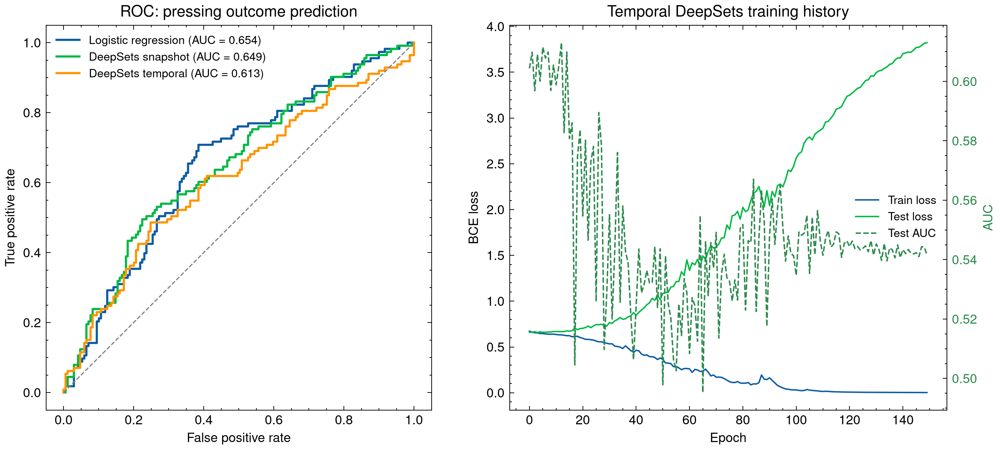

In [20]:
from sklearn.metrics import roc_curve

# --- Temporal model metrics ---
model_t.eval()
with torch.no_grad():
    xt, mt, yt = next(iter(test_loader_t))
    td_probs = torch.sigmoid(model_t(xt, mt)).numpy()
    td_labels = yt.numpy()

td_auc = roc_auc_score(td_labels, td_probs)
td_ap = average_precision_score(td_labels, td_probs)
td_acc = ((td_probs > 0.5) == td_labels).mean()

print("Model comparison:\n")
print(f"  {'Model':30s} {'Accuracy':>8s}  {'AUC':>6s}  {'AP':>6s}")
print(f"  {'-'*30} {'-'*8}  {'-'*6}  {'-'*6}")
print(f"  {'Logistic regression':30s} {acc:8.3f}  {auc:6.3f}  {ap:6.3f}")
print(f"  {'DeepSets (snapshot)':30s} {dl_acc:8.3f}  {dl_auc:6.3f}  {dl_ap:6.3f}")
print(f"  {'DeepSets + Conv1d (temporal)':30s} {td_acc:8.3f}  {td_auc:6.3f}  {td_ap:6.3f}")

# --- ROC curves + training history ---
fpr_td, tpr_td, _ = roc_curve(td_labels, td_probs)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

ax = axes[0]
ax.plot(fpr_lr, tpr_lr, lw=1.5, label=f"Logistic regression (AUC = {auc:.3f})")
ax.plot(fpr_dl, tpr_dl, lw=1.5, label=f"DeepSets snapshot (AUC = {dl_auc:.3f})")
ax.plot(fpr_td, tpr_td, lw=1.5, label=f"DeepSets temporal (AUC = {td_auc:.3f})")
ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=0.8)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC: pressing outcome prediction")
ax.legend(fontsize=8)
ax.set_aspect("equal")

ax = axes[1]
ax.plot(history_t["train_loss"], label="Train loss", lw=1)
ax.plot(history_t["test_loss"], label="Test loss", lw=1)
ax2 = ax.twinx()
ax2.plot(history_t["test_auc"], color="#2d8a4e", ls="--", lw=1, label="Test AUC")
ax.set_xlabel("Epoch")
ax.set_ylabel("BCE loss")
ax2.set_ylabel("AUC", color="#2d8a4e")
ax2.tick_params(axis="y", labelcolor="#2d8a4e")
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc="center right")
ax.set_title("Temporal DeepSets training history")

plt.tight_layout()
plt.show()

## Interpretation: does pressing aggressiveness pay off?

In [55]:
# --- Raw pressing outcome rates by home/away ---
home_press = feat_df[feat_df["is_home"] == 1]
away_press = feat_df[feat_df["is_home"] == 0]

home_regain = home_press["label"].mean()
away_regain = away_press["label"].mean()

print(f"Home pressing: {len(home_press)} chains, "
      f"{int(home_press['label'].sum())} regain, "
      f"{len(home_press) - int(home_press['label'].sum())} disruption "
      f"({home_regain:.1%} regain rate)")
print(f"Away pressing: {len(away_press)} chains, "
      f"{int(away_press['label'].sum())} regain, "
      f"{len(away_press) - int(away_press['label'].sum())} disruption "
      f"({away_regain:.1%} regain rate)")

from scipy.stats import chi2_contingency
table = pd.crosstab(feat_df["is_home"], feat_df["label"])
chi2, p, dof, _ = chi2_contingency(table)
print(f"Chi-squared test: χ²={chi2:.2f}, p={p:.3f}")

Home pressing: 739 chains, 316 regain, 423 disruption (42.8% regain rate)
Away pressing: 671 chains, 251 regain, 420 disruption (37.4% regain rate)
Chi-squared test: χ²=3.97, p=0.046


python(3855) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3856) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3857) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3859) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3860) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3861) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3862) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3863) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3864) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3865) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(3866) MallocStackLoggin

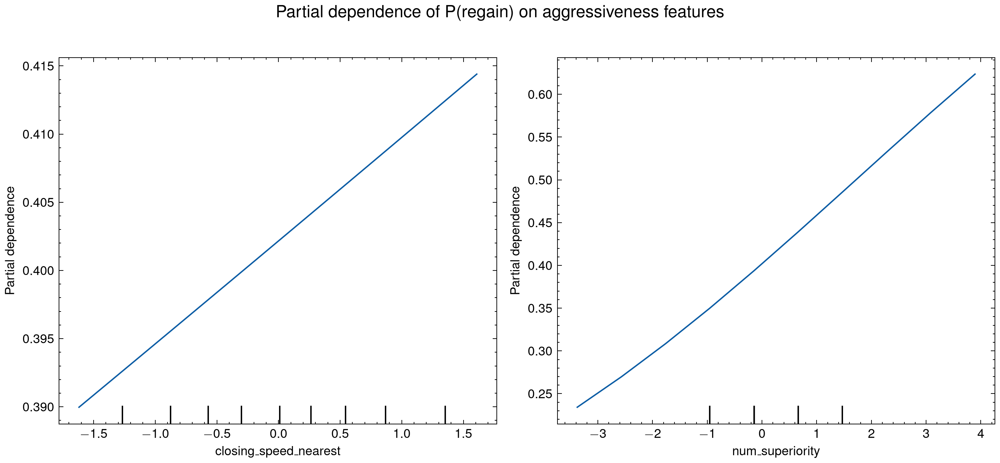

In [43]:
# --- Partial dependence of P(regain) on aggressiveness features ---
# For each feature, vary it across its observed range while keeping all other
# features at their observed values, and average the model's P(regain).

from sklearn.inspection import PartialDependenceDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

cs_idx = feature_cols.index("closing_speed_nearest")
ns_idx = feature_cols.index("num_superiority")

for ax, feat, label in [
    (axes[0], "closing_speed_nearest", "Closing speed, 3 nearest (m/s)"),
    (axes[1], "num_superiority", "Numerical superiority (15m radius)"),
]:
    fidx = feature_cols.index(feat)
    display = PartialDependenceDisplay.from_estimator(
        clf, X_train_s, [fidx],
        feature_names=feature_cols,
        kind="average",
        ax=ax,
    )
    ax.set_ylabel("Partial dependence\n(≈ P(regain))")
    ax.set_xlabel(label)
    ax.set_title("")

fig.suptitle(
    "Partial dependence of P(regain) on aggressiveness features",
    fontsize=12, fontweight="bold", y=1.02,
)
plt.tight_layout()
plt.show()

python(4961) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4963) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4964) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4965) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4966) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4967) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4968) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4969) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4970) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4975) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4978) MallocStackLoggin

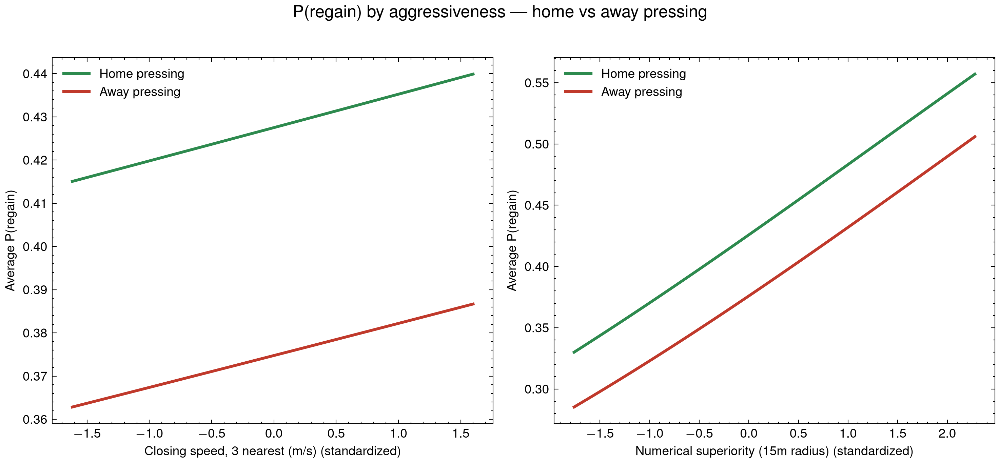

In [44]:
# --- Partial dependence stratified by home/away pressing ---
home_mask_train = X_train[:, feature_cols.index("is_home")] == 1
away_mask_train = ~home_mask_train

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

for ax, feat, label in [
    (axes[0], "closing_speed_nearest", "Closing speed, 3 nearest (m/s)"),
    (axes[1], "num_superiority", "Numerical superiority (15m radius)"),
]:
    fidx = feature_cols.index(feat)
    grid_values = np.linspace(
        np.percentile(X_train_s[:, fidx], 5),
        np.percentile(X_train_s[:, fidx], 95),
        50,
    )

    for mask, color, lbl in [
        (home_mask_train, "#2d8a4e", "Home pressing"),
        (away_mask_train, "#c0392b", "Away pressing"),
    ]:
        X_sub = X_train_s[mask]
        preds = []
        for val in grid_values:
            X_mod = X_sub.copy()
            X_mod[:, fidx] = val
            preds.append(clf.predict_proba(X_mod)[:, 1].mean())
        ax.plot(grid_values, preds, color=color, lw=2, label=lbl)

    ax.set_ylabel("Average P(regain)")
    ax.set_xlabel(label + " (standardized)")
    ax.legend(fontsize=9)

fig.suptitle(
    "P(regain) by aggressiveness — home vs away pressing",
    fontsize=12, fontweight="bold", y=1.02,
)
plt.tight_layout()
plt.show()

python(4989) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4990) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4991) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4992) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4993) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4994) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4995) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4996) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(4998) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


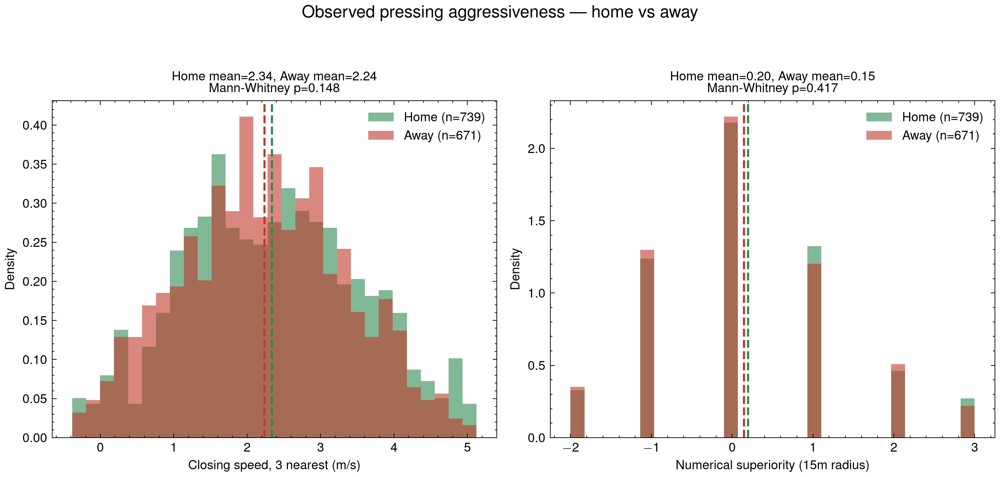

In [45]:
# --- Observed aggressiveness: home vs away ---
home_df = feat_df[feat_df["is_home"] == 1]
away_df = feat_df[feat_df["is_home"] == 0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

for ax, col, label in [
    (axes[0], "closing_speed_nearest", "Closing speed, 3 nearest (m/s)"),
    (axes[1], "num_superiority", "Numerical superiority (15m radius)"),
]:
    bins = np.linspace(
        feat_df[col].quantile(0.01),
        feat_df[col].quantile(0.99),
        30,
    )
    ax.hist(home_df[col], bins=bins, alpha=0.6, color="#2d8a4e",
            label=f"Home (n={len(home_df)})", density=True)
    ax.hist(away_df[col], bins=bins, alpha=0.6, color="#c0392b",
            label=f"Away (n={len(away_df)})", density=True)

    h_mean = home_df[col].mean()
    a_mean = away_df[col].mean()
    ax.axvline(h_mean, color="#2d8a4e", ls="--", lw=1.5)
    ax.axvline(a_mean, color="#c0392b", ls="--", lw=1.5)

    ax.set_xlabel(label)
    ax.set_ylabel("Density")
    ax.legend(fontsize=9)

    from scipy.stats import mannwhitneyu
    stat, pval = mannwhitneyu(home_df[col], away_df[col], alternative="two-sided")
    ax.set_title(f"Home mean={h_mean:.2f}, Away mean={a_mean:.2f}\nMann-Whitney p={pval:.3f}",
                 fontsize=9)

fig.suptitle(
    "Observed pressing aggressiveness — home vs away",
    fontsize=12, fontweight="bold", y=1.05,
)
plt.tight_layout()
plt.show()

## Summary

This notebook asked whether pressing aggressiveness is effective, and whether the home advantage in pressing (documented in the territorial behavior analysis) can be explained by differences in pressing style.

**Pressing outcome prediction.** We trained three models to predict pressing outcome (regain vs. disruption) from player tracking data: a logistic regression on hand-crafted features, a permutation-invariant DeepSets model on raw player configurations, and a temporal DeepSets extension using five keyframes per pressing chain. The logistic regression and snapshot DeepSets performed similarly (AUC 0.65-0.67), while the temporal model underperformed, likely because 1,410 pressing chains are too few for the model to learn that earlier keyframes add little predictive signal beyond the end-of-chain snapshot.

**Does pressing aggressiveness pay off?** Partial dependence analysis shows that both dimensions of aggressiveness increase the probability of regain: higher closing speed (contesting harder) and greater numerical superiority near the ball (contesting with more players) both raise P(regain). The effect of numerical superiority is stronger than that of closing speed.

**Home advantage in pressing efficiency.** Home pressing succeeds more often than away pressing (42.8% vs. 37.4% regain rate, p=0.046), confirming a home advantage in pressing effectiveness. However, home and away teams press with statistically indistinguishable intensity: neither closing speed nor numerical superiority differs significantly between home and away pressing. The model confirms this pattern: the home advantage in P(regain) is additive and does not interact with pressing style. Home teams do not press differently, yet their pressing is more effective.

**Interpretation.** Combined with the finding from the territorial behavior analysis that home teams press more frequently, we observe that the home advantage in pressing operates along two dimensions: home teams press both more often and more effectively. The efficiency gap is not explained by observable differences in pressing intensity or spatial configuration, suggesting that the mechanism operates through channels not captured by tracking data alone. Possible channels include psychological effects (possibly via crowd influence) that may influence the skills of the away team in holding the ball, or the determination of the home team in pressing the opponent.